In [2]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
# Load the Data
df = pd.read_csv("taiwan_bankruptcy_clean.csv")

In [3]:
#Function to cap extreme outliers (Winsorization at 1% and 99%)
def winsorize(series, p=0.01):
    lower = series.quantile(p)
    upper = series.quantile(1 - p)
    return series.clip(lower, upper)

In [4]:
#Apply winsorization to all columns except the target 'Class'
df_wins = df.copy()
for col in df.columns:
    if col != "Class":
        df_wins[col] = winsorize(df_wins[col])

In [5]:
#Select a subset of meaningful financial features
vars_candidates = [
    "Net_Income_to_Total_Assets",
    "Debt_ratio",
    "Working_Capital_to_Total_Assets",
    "Retained_Earnings_to_Total_Assets",
    "Borrowing_dependency",
    "Persistent_EPS_in_the_Last_Four_Seasons",
    "Current_Liability_to_Current_Assets"
]


In [6]:
# Check that all exist in the dataframe
vars_candidates = [v for v in vars_candidates if v in df_wins.columns]
vars_candidates

['Net_Income_to_Total_Assets',
 'Debt_ratio',
 'Working_Capital_to_Total_Assets',
 'Retained_Earnings_to_Total_Assets',
 'Borrowing_dependency',
 'Persistent_EPS_in_the_Last_Four_Seasons',
 'Current_Liability_to_Current_Assets']

In [7]:
# Define X (independent variables/features) and y (target/dependent variable)
X = df_wins[vars_candidates]
y = df_wins["Class"]
print(f"\nShape of X (features): {X.shape}")



Shape of X (features): (6819, 7)


CHECKING FOR MULTICOLLINEARITY (VIF)

In [8]:
#Create a DataFrame to store the VIF results for each selected feature
vif_data = pd.DataFrame()
vif_data['Variable'] = X.columns 
vif_data

,Variable
0,Net_Income_to_Total_Assets
1,Debt_ratio
2,Working_Capital_to_Total_Assets
3,Retained_Earnings_to_Total_Assets
4,Borrowing_dependency
5,Persistent_EPS_in_the_Last_Four_Seasons
6,Current_Liability_to_Current_Assets


In [9]:
# Calculate VIF for each column index
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
#Sort the results to see the highest VIF values first
vif_data = vif_data.sort_values(by="VIF", ascending=False).reset_index(drop=True)
vif_data 

,Variable,VIF
0,Net_Income_to_Total_Assets,6.276592
1,Current_Liability_to_Current_Assets,3.930645
2,Persistent_EPS_in_the_Last_Four_Seasons,3.734870
3,Retained_Earnings_to_Total_Assets,3.490875
4,Working_Capital_to_Total_Assets,3.434219
5,Debt_ratio,3.070450
6,Borrowing_dependency,2.859000


In [10]:
#. SPLIT TRAIN/TEST (70/30, stratified given the imbalance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=123, stratify=y
)
print(f"Training data size X_train: {len(X_train)}")
print(f"Test data size X_test: {len(X_test)}")
print(f"Bankruptcy rate in training data: {y_train.mean()*100:.2f}%")
print(f"Bankruptcy rate in test data: {y_test.mean()*100:.2f}%")

Training data size X_train: 4773
Test data size X_test: 2046
Bankruptcy rate in training data: 3.23%
Bankruptcy rate in test data: 3.23%


ESTIMATION OF LOGIT AND PROBIT MODELS (statsmodels)

In [11]:
# Add a constant (intercept) to the independent variables because statistical models require it
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)
# Estimate the Logistic Regression model (Logit)
logit_model = sm.Logit(y_train, X_train_sm).fit()
# Estimate the Probit model
probit_model = sm.Probit(y_train, X_train_sm).fit()


Optimization terminated successfully.
         Current function value: 0.087426
         Iterations 10
Optimization terminated successfully.
         Current function value: 0.085715
         Iterations 9


In [12]:
#Print the summary results of the Logit model
print("---Logit Model Summary---")
print(logit_model.summary())

---Logit Model Summary---
                           Logit Regression Results                           
Dep. Variable:                  Class   No. Observations:                 4773
Model:                          Logit   Df Residuals:                     4765
Method:                           MLE   Df Model:                            7
Date:                Sun, 08 Nov 2026   Pseudo R-squ.:                  0.3866
Time:                        22:15:38   Log-Likelihood:                -417.28
converged:                       True   LL-Null:                       -680.29
Covariance Type:            nonrobust   LLR p-value:                2.042e-109
                                              coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
const                                       1.9050      8.525      0.223      0.823     -14.803      18.613
Net_Income_to_Tota

In [13]:
#Print the summary results of the Probit model
print("--- Probit Model Summary ---")
print(probit_model.summary())

--- Probit Model Summary ---
                          Probit Regression Results                           
Dep. Variable:                  Class   No. Observations:                 4773
Model:                         Probit   Df Residuals:                     4765
Method:                           MLE   Df Model:                            7
Date:                Sun, 08 Nov 2026   Pseudo R-squ.:                  0.3986
Time:                        22:15:38   Log-Likelihood:                -409.12
converged:                       True   LL-Null:                       -680.29
Covariance Type:            nonrobust   LLR p-value:                6.278e-113
                                              coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
const                                      -1.6309      4.525     -0.360      0.719     -10.500       7.238
Net_Income_to_T

Predictions and Evaluation on the Test Sample

In [14]:
#Predict bankruptcy probabilities on the test set
pred_logit = logit_model.predict(X_test_sm)
pred_probit = probit_model.predict(X_test_sm)

In [25]:
#Calculate ROC-AUC scores (measures overall model discrimination power)
auc_logit = roc_auc_score(y_test, pred_logit)
auc_probit = roc_auc_score(y_test, pred_probit)
print(f"\nAUC logit  : {auc_logit:.4f}")
print(f"AUC probit : {auc_probit:.4f}")


AUC logit  : 0.9291
AUC probit : 0.9293


In [16]:
#Convert probabilities to binary classes (0 or 1) using a standard 0.5 threshold
y_pred_logit_class = (pred_logit>= 0.5).astype(int)
y_pred_probit_class = (pred_probit >= 0.5).astype(int)

In [22]:
#Print Confusion Matrix for Logit/ probit
print("\n--- Logit Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_logit_class))
print('---Probit Cinfusin Matrix ---')
print(confusion_matrix(y_test, y_pred_probit_class))


--- Logit Confusion Matrix ---
[[1969   11]
 [  56   10]]
---Probit Cinfusin Matrix ---
[[1970   10]
 [  57    9]]


In [23]:
print(classification_report(y_test, y_pred_logit_class))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1980
           1       0.48      0.15      0.23        66

    accuracy                           0.97      2046
   macro avg       0.72      0.57      0.61      2046
weighted avg       0.96      0.97      0.96      2046



In [18]:
#Caculate marginal effects for the logit model at the mean of the variables
marginal_effects = logit_model.get_margeff(at='mean')
marginal_effects.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
        Logit Marginal Effects       
=====================================
Dep. Variable:                  Class
Method:                          dydx
At:                              mean
===========================================================================================================
                                             dy/dx    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
Net_Income_to_Total_Assets                 -0.0219      0.045     -0.490      0.624      -0.109       0.066
Debt_ratio                                  0.0757      0.023      3.296      0.001       0.031       0.121
Working_Capital_to_Total_Assets             0.0132      0.025      0.529      0.597      -0.036       0.062
Retained_Earnings_to_Total_Assets          -0.1130      0.050     -2.260      0.024      -0.211      -0.015
Borrowing_dependency                        0.2965      0.140      2.111      0.035       0.021       0.572
Persistent_EPS_in_the_Last_Four_Seasons    -0.2514      0.067     -3.754      0.000      -0.383      -0.120
Current_Liability_to_Current_Assets         0.1211      0.056      2.167      0.030       0.012       0.231
===========================================================================================================
"""

 Exploratory Visualizations

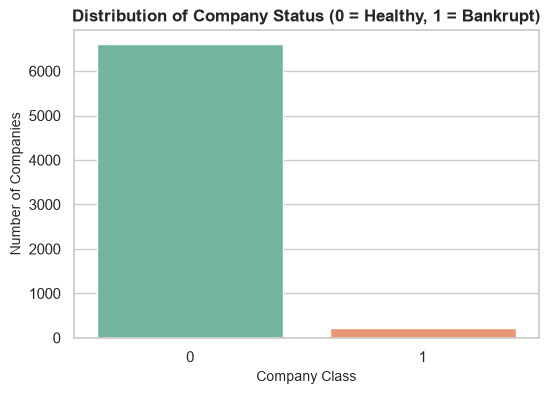

In [ ]:
## Distribution of company status
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 4))
sns.countplot(x=df['Class'], palette='Set2', hue =df['Class'], legend = False)
plt.title('Distribution of Company Status (0 = Healthy, 1 = Bankrupt)', fontsize=12, fontweight='bold')
plt.xlabel('Company Class', fontsize=10)
plt.ylabel('Number of Companies', fontsize=10)
plt.show()

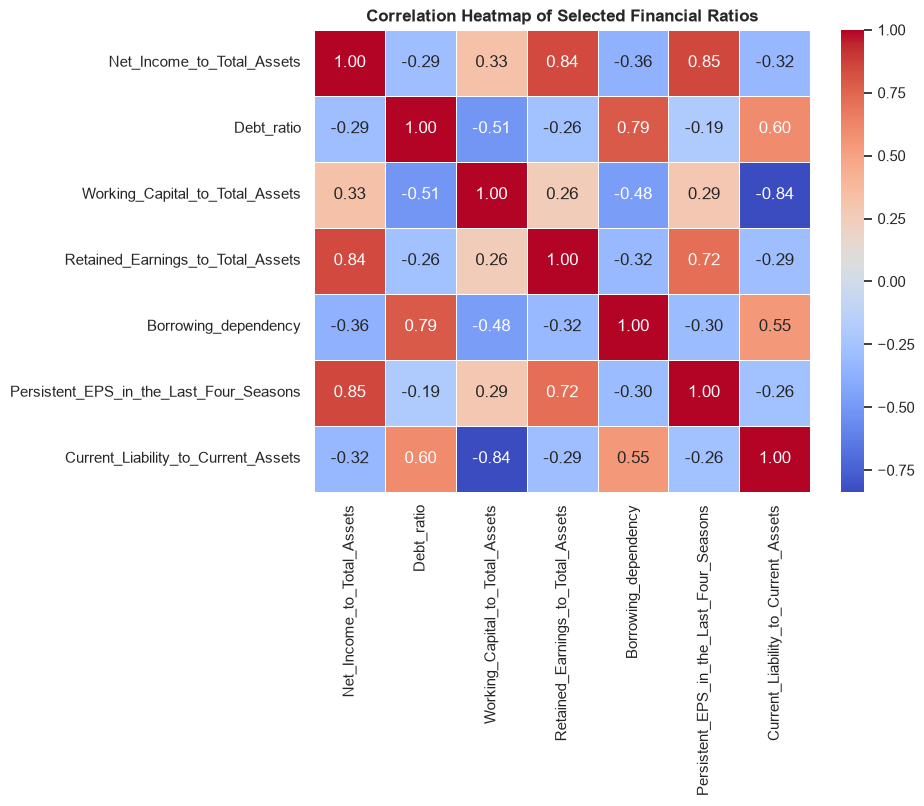

In [ ]:
#  Correlation heatmap of selected financial ratios
plt.figure(figsize=(8, 6))
# Calculate correlation matrix for our selected features
corr_matrix = X.corr()

# Draw the heatmap using Seaborn
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Selected Financial Ratios', fontsize=12, fontweight='bold')
plt.show()